In [1]:
import numpy as np

# reload the original free-chem if not in memory
free = np.load("free_chem_data/clean_final_spec.npy")   # adjust path

# param columns: [Rstar, Rp, Mp, T, logH2O, logCH4, logCO, logCO2, logNH3, na]
param_names = ["Rstar_Rs", "Rp_Rj", "Mp_Mj", "T",
               "log_H2O", "log_CH4", "log_CO", "log_CO2", "log_NH3", "na"]

print("Ranges in the original free-chem dataset:")
for i, name in enumerate(param_names):
    col = free[:, 52 + i]
    print(f"  {name:10s}: {col.min():8.3f}  to  {col.max():8.3f}")

Ranges in the original free-chem dataset:
  Rstar_Rs  :    0.500  to     2.000
  Rp_Rj     :    0.100  to     2.000
  Mp_Mj     :    0.011  to     5.000
  T         :  300.006  to  2999.985
  log_H2O   :   -9.000  to    -3.000
  log_CH4   :   -9.000  to    -3.000
  log_CO    :   -9.000  to    -3.000
  log_CO2   :   -9.000  to    -3.000
  log_NH3   :   -9.000  to    -3.000
  na        :    1.000  to     1.000


In [2]:
import numpy as np
import pickle, os, time
import spectres
from POSEIDON.core import (create_star, create_planet, define_model,
                            make_atmosphere, compute_spectrum, wl_grid_constant_R)
from POSEIDON.constants import R_J, M_J, R_Sun

# slimmed opacity file (5 molecules) - same one you used for ACE equilibrium
with open("opacities_created/opac_eq_chemistry.pickle", "rb") as f:   # adjust path
    opac = pickle.load(f)
print("Opacity loaded")

target_species = ["H2O", "CH4", "CO", "CO2", "NH3"]
pressure_bar = np.logspace(3, -6, 100)        # YOUR grid (matches equi/disequi)
wl_min, wl_max, R_highres = 0.4, 10.0, 15000
wl_highres = wl_grid_constant_R(wl_min, wl_max, R_highres)
wl_binned = np.load("equi_chem_data/wl_binned.npy")   # adjust path

model = define_model("free_chem_model", ["H2", "He"], target_species,
                     PT_profile="file_read", X_profile="file_read")
star = create_star(1.0 * R_Sun, 5778.0, 4.44, 0.0)
print("Model, star, grids ready")

Opacity loaded
Model, star, grids ready


In [3]:
SEED = 42
N_PLANETS = 10000
rng = np.random.default_rng(SEED)

# planet params - matched to equi/disequi ranges
Teq   = rng.uniform(300.0, 3000.0, N_PLANETS)   # start at 437 to match temp range
Rp    = rng.uniform(0.1, 2.0, N_PLANETS)
Mp    = rng.uniform(0.1, 5.0, N_PLANETS)         # matched floor 0.1, not 0.011
Rstar = rng.uniform(0.5, 2.0, N_PLANETS)

# free abundances - log-uniform from -9 to -3, independent per molecule
log_abund = rng.uniform(-9.0, -3.0, size=(N_PLANETS, 5))   # cols: H2O,CH4,CO,CO2,NH3

print("Sampled", N_PLANETS, "free-chem planets")
print("Teq range:", Teq.min(), "-", Teq.max())
print("log-abundance range:", log_abund.min(), "-", log_abund.max())

# save the table so params are never lost
np.savez("free_chem_params.npz", Teq=Teq, Rp=Rp, Mp=Mp, Rstar=Rstar, log_abund=log_abund)

Sampled 10000 free-chem planets
Teq range: 300.8489330390348 - 2999.9379551277743
log-abundance range: -8.999920306168807 - -3.000037600235957


In [4]:
def build_X_input(log_abund_row):
    """
    Free chem: each molecule has a CONSTANT vertical profile (same at all layers).
    log_abund_row = [logH2O, logCH4, logCO, logCO2, logNH3]
    """
    n = len(pressure_bar)
    vmr = 10.0 ** log_abund_row   # convert log -> linear VMR (5 values)
    return np.array([
        np.full(n, 0.83), np.full(n, 0.17),        # H2, He bulk
        np.full(n, vmr[0]),  # H2O constant
        np.full(n, vmr[1]),  # CH4
        np.full(n, vmr[2]),  # CO
        np.full(n, vmr[3]),  # CO2
        np.full(n, vmr[4]),  # NH3
    ])

def generate_spectrum(i):
    R_p = Rp[i] * R_J
    M_p = Mp[i] * M_J
    planet = create_planet("planet", R_p, mass=M_p, T_eq=Teq[i])
    T_input = np.full(len(pressure_bar), Teq[i])     # isothermal
    X_input = build_X_input(log_abund[i])
    atmosphere = make_atmosphere(planet, model, pressure_bar, 10.0, R_p,
                                 T_input=T_input, X_input=X_input)
    if not atmosphere["is_physical"]:
        return None, False
    spec = compute_spectrum(planet, star, model, atmosphere, opac, wl_highres,
                            spectrum_type="transmission")
    return spec, True

In [5]:
spec, ok = generate_spectrum(0)
if ok:
    print(f"mean={spec.mean():.3e}, std={spec.std():.3e}, std/mean={spec.std()/spec.mean():.2e}")
    print(f"nan={np.any(np.isnan(spec))}")
else:
    print("NOT physical")

mean=2.357e-02, std=2.835e-04, std/mean=1.20e-02
nan=False


In [5]:
OUT_DIR = "free_chem_spectra_output"
os.makedirs(OUT_DIR, exist_ok=True)

already = set(int(f.split("_")[1].split(".")[0])
              for f in os.listdir(OUT_DIR) if f.startswith("spec_"))
print(f"{len(already)} done, {N_PLANETS - len(already)} remaining")

t0 = time.time(); n_proc = 0
for i in range(N_PLANETS):
    if i in already:
        continue
    try:
        spec, ok = generate_spectrum(i)
        if ok and not (np.any(np.isnan(spec)) or np.any(np.isinf(spec))):
            sb = spectres.spectres(wl_binned, wl_highres, spec, verbose=False)
            np.save(os.path.join(OUT_DIR, f"spec_{i:05d}.npy"), sb)
    except Exception:
        pass
    n_proc += 1
    if n_proc % 100 == 0:
        rate = (time.time()-t0)/n_proc
        print(f"{i}/{N_PLANETS} | {rate:.1f}s/planet | ~{(N_PLANETS-i)*rate/60:.0f} min left", flush=True)

print(f"\nDone. {(time.time()-t0)/60:.1f} min")

8852 done, 1148 remaining
8951/10000 | 1.0s/planet | ~17 min left
9051/10000 | 0.9s/planet | ~14 min left
9151/10000 | 1.0s/planet | ~14 min left
9251/10000 | 0.9s/planet | ~11 min left
9351/10000 | 0.9s/planet | ~10 min left
9451/10000 | 0.9s/planet | ~9 min left
9551/10000 | 0.9s/planet | ~7 min left
9651/10000 | 0.9s/planet | ~6 min left
9751/10000 | 1.0s/planet | ~4 min left
9851/10000 | 1.0s/planet | ~2 min left
9951/10000 | 1.0s/planet | ~1 min left

Done. 18.3 min


In [11]:
import json

OUT_DIR = "free_chem_spectra_output"
os.makedirs(OUT_DIR, exist_ok=True)

# a single JSON that accumulates params for every successful spectrum
params_log_path = os.path.join(OUT_DIR, "params_all_free.json")

already = set(int(f.split("_")[1].split(".")[0])
              for f in os.listdir(OUT_DIR) if f.startswith("spec_"))
print(f"{len(already)} done, {N_PLANETS - len(already)} remaining")

# load existing params log if resuming, else start fresh
if os.path.exists(params_log_path):
    with open(params_log_path) as f:
        params_log = json.load(f)
else:
    params_log = {}

t0 = time.time(); n_proc = 0
for i in range(N_PLANETS):
    if i in already:
        continue
    try:
        spec, ok = generate_spectrum(i)
        if ok and not (np.any(np.isnan(spec)) or np.any(np.isinf(spec))):
            sb = spectres.spectres(wl_binned, wl_highres, spec, verbose=False)
            np.save(os.path.join(OUT_DIR, f"spec_{i:05d}.npy"), sb)
            # record this planet's params
            params_log[f"{i:05d}"] = {
                "Teq_K": float(Teq[i]),
                "Rp_Rj": float(Rp[i]),
                "Mp_Mj": float(Mp[i]),
                "Rstar_Rs": float(Rstar[i]),
                "log_H2O": float(log_abund[i, 0]),
                "log_CH4": float(log_abund[i, 1]),
                "log_CO":  float(log_abund[i, 2]),
                "log_CO2": float(log_abund[i, 3]),
                "log_NH3": float(log_abund[i, 4]),
            }
    except Exception:
        pass
    n_proc += 1
    if n_proc % 100 == 0:
        rate = (time.time()-t0)/n_proc
        print(f"{i}/{N_PLANETS} | {rate:.1f}s/planet | ~{(N_PLANETS-i)*rate/60:.0f} min left", flush=True)
        # periodically save the params log so it's never lost
        with open(params_log_path, "w") as f:
            json.dump(params_log, f)

# final save of the params log
with open(params_log_path, "w") as f:
    json.dump(params_log, f, indent=2)

print(f"\nDone. {(time.time()-t0)/60:.1f} min. Params saved to {params_log_path}")

9972 done, 28 remaining

Done. 0.0 min. Params saved to free_chem_spectra_output/params_all_free.json


In [7]:
import numpy as np, glob, os
import matplotlib.pyplot as plt

OUT_DIR = "free_chem_spectra_output"
files = sorted(glob.glob(os.path.join(OUT_DIR, "spec_*.npy")))
print(f"Total spectra generated: {len(files)}")

# load a random sample of 200 to check validity
rng = np.random.default_rng(0)
sample_files = rng.choice(files, min(200, len(files)), replace=False)
sample = np.array([np.load(f) for f in sample_files])

# each spectrum's std/mean - the "is it flat?" metric
std_over_mean = sample.std(axis=1) / sample.mean(axis=1)

print("std/mean stats across 200 spectra:")
print("  min: ", std_over_mean.min())
print("  median:", np.median(std_over_mean))
print("  max: ", std_over_mean.max())
print()
print("Flat/broken spectra (std/mean < 1e-6):", np.sum(std_over_mean < 1e-6))

Total spectra generated: 9972
std/mean stats across 200 spectra:
  min:  6.589636392704339e-05
  median: 0.0039564375704425605
  max:  0.3130841320566888

Flat/broken spectra (std/mean < 1e-6): 0


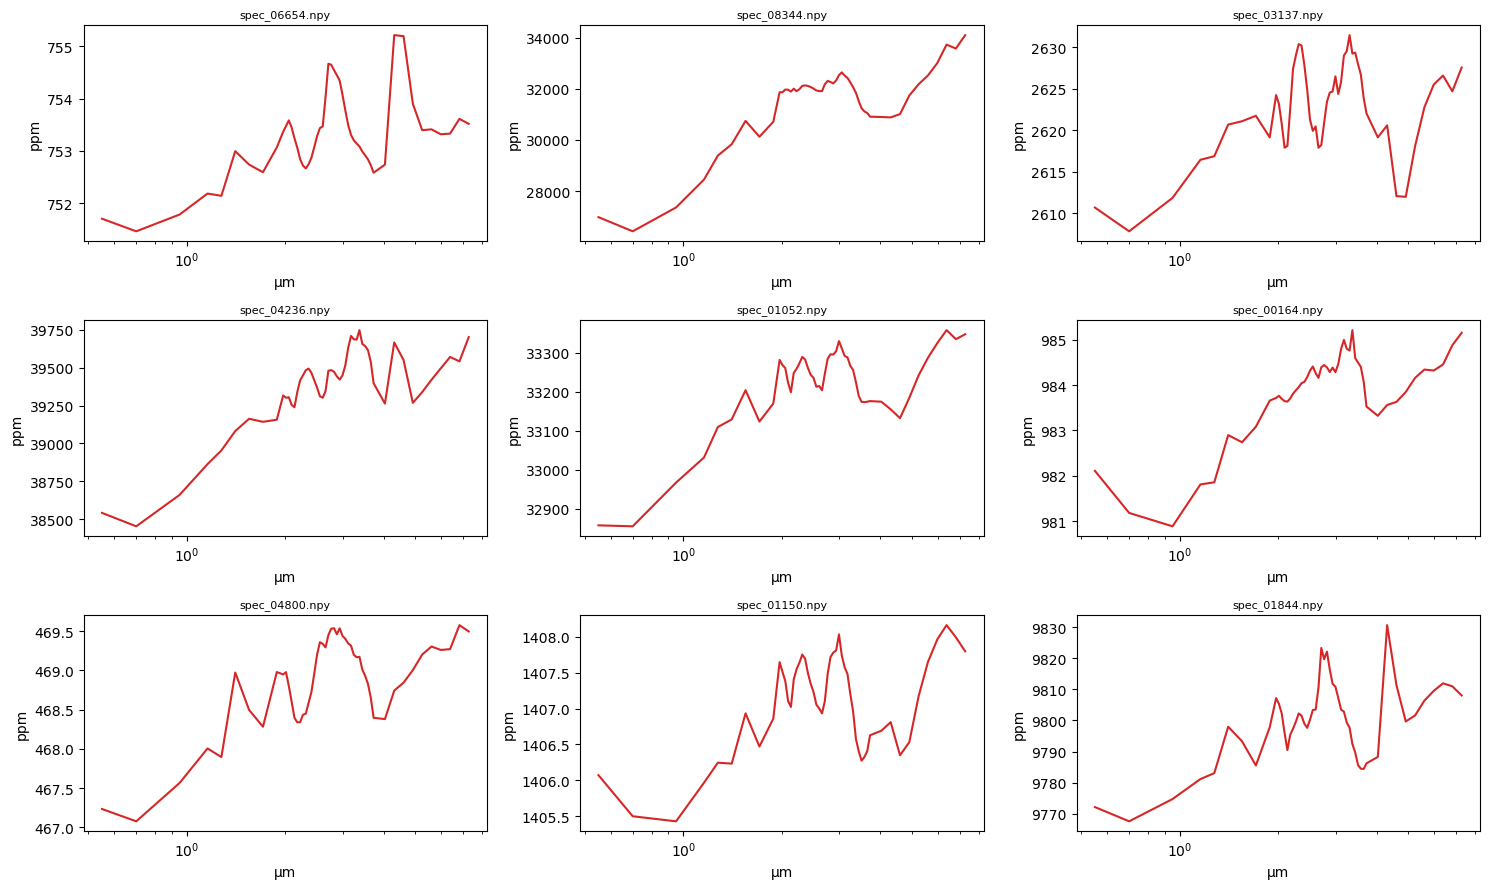

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(15, 9))
wl_binned = np.load("equi_chem_data/wl_binned.npy")   # adjust path

for ax, f in zip(axes.flat, sample_files[:9]):
    spec = np.load(f)
    ax.plot(wl_binned, spec * 1e6, color="tab:red")
    ax.set_title(os.path.basename(f), fontsize=8)
    ax.set_xscale("log")
    ax.set_xlabel("μm"); ax.set_ylabel("ppm")

plt.tight_layout()
plt.show()

In [8]:
i = 0
X = build_X_input(log_abund[i])
print("H2O profile (should be constant):", X[2][:3], "...", X[2][-3:])
print("All same?", np.allclose(X[2], X[2][0]))

H2O profile (should be constant): [5.60426333e-08 5.60426333e-08 5.60426333e-08] ... [5.60426333e-08 5.60426333e-08 5.60426333e-08]
All same? True
